**Import Required Libraries**

In [1]:
import warnings
import json
import joblib

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


**Configure Project Paths**

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
RESULTS_FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_METRICS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Processed Data:", DATA_PROCESSED_DIR)
print("Models:", MODELS_DIR)
print("Metrics:", RESULTS_METRICS_DIR)
print("Figures:", RESULTS_FIGURES_DIR)

Project Root: D:\AI-IDS
Processed Data: D:\AI-IDS\data\processed
Models: D:\AI-IDS\models
Metrics: D:\AI-IDS\results\metrics
Figures: D:\AI-IDS\results\figures


**Load Test Dataset**

In [3]:
test_path = DATA_PROCESSED_DIR / "test.csv"

if not test_path.exists():
    raise FileNotFoundError(
        f"Test dataset not found: {test_path}"
    )

test_df = pd.read_csv(test_path)

print("Test dataset loaded successfully.")
print()
print("Test dataset shape:", test_df.shape)

Test dataset loaded successfully.

Test dataset shape: (378120, 75)


**Load Feature Configuration**

In [4]:
feature_config_path = DATA_PROCESSED_DIR / "feature_config.json"

if not feature_config_path.exists():
    raise FileNotFoundError(
        f"Feature configuration not found: {feature_config_path}"
    )

with open(feature_config_path, "r") as file:
    feature_config = json.load(file)

feature_columns = feature_config["features"]

print("Number of features:", len(feature_columns))
print()

print("First 20 features:")
for feature in feature_columns[:20]:
    print(" -", feature)

Number of features: 74

First 20 features:
 - Destination_Port
 - Flow_Duration
 - Total_Fwd_Packets
 - Total_Backward_Packets
 - Total_Length_of_Fwd_Packets
 - Total_Length_of_Bwd_Packets
 - Fwd_Packet_Length_Max
 - Fwd_Packet_Length_Min
 - Fwd_Packet_Length_Mean
 - Fwd_Packet_Length_Std
 - Bwd_Packet_Length_Max
 - Bwd_Packet_Length_Min
 - Bwd_Packet_Length_Mean
 - Bwd_Packet_Length_Std
 - Flow_Bytess
 - Flow_Packetss
 - Flow_IAT_Mean
 - Flow_IAT_Std
 - Flow_IAT_Max
 - Flow_IAT_Min


**Prepare Test Features and Target**

In [5]:
# Verify all required features exist
missing_features = [
    feature
    for feature in feature_columns
    if feature not in test_df.columns
]

if missing_features:
    raise KeyError(
        f"The following features are missing from the test dataset: "
        f"{missing_features}"
    )

X_test = test_df[feature_columns].copy()
y_test = test_df["Attack"].copy()

print("Test feature matrix shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Test feature matrix shape: (378120, 74)
Test target shape: (378120,)


**Verify Test Dataset**

In [6]:
def class_distribution(y):
    result = pd.DataFrame({
        "Count": y.value_counts(),
        "Percentage": y.value_counts(normalize=True) * 100
    })

    result.index = result.index.map({
        0: "BENIGN",
        1: "ATTACK"
    })

    return result

print("Test Class Distribution:")
display(class_distribution(y_test))

print("\nMissing values:")
print("Features:", X_test.isnull().sum().sum())
print("Target:", y_test.isnull().sum())

print("\nInfinite values:")
print("Features:", np.isinf(X_test).sum().sum())

print("\nUnique target values:")
print(sorted(y_test.unique()))

Test Class Distribution:


,Count,Percentage
Attack,,
BENIGN,314259,83.110917
ATTACK,63861,16.889083



Missing values:
Features: 0
Target: 0

Infinite values:
Features: 0

Unique target values:
[np.int64(0), np.int64(1)]


**Load Final Trained Model**

In [8]:
model_path = MODELS_DIR / "final_ids_model.pkl"
metadata_path = MODELS_DIR / "model_metadata.json"

if not model_path.exists():
    raise FileNotFoundError(
        f"Final model not found: {model_path}\n"
        "Run 02_model_development.ipynb first."
    )

if not metadata_path.exists():
    raise FileNotFoundError(
        f"Model metadata not found: {metadata_path}\n"
        "Run 02_model_development.ipynb first."
    )

final_model = joblib.load(model_path)

with open(metadata_path, "r") as file:
    model_metadata = json.load(file)

print("Final model loaded successfully.")
print()
print("Selected Model:", model_metadata["selected_model"])
print("Dataset:", model_metadata["dataset"])
print("Task:", model_metadata["task"])
print("Number of Features:", model_metadata["number_of_features"])

Final model loaded successfully.

Selected Model: Random Forest
Dataset: CICIDS2017
Task: Binary Intrusion Detection
Number of Features: 74


**Verify Model and Feature Configuration**

In [9]:
if len(feature_columns) != model_metadata["number_of_features"]:
    raise ValueError(
        "Feature count mismatch between feature configuration and model metadata."
    )

if feature_columns != model_metadata["features"]:
    raise ValueError(
        "Feature order mismatch between feature configuration and model metadata."
    )

print("Model and feature configuration verified successfully.")
print("Feature count:", len(feature_columns))
print("Selected model:", model_metadata["selected_model"])

Model and feature configuration verified successfully.
Feature count: 74
Selected model: Random Forest


**Generate Test Predictions**

In [10]:
print("Generating predictions on test dataset...")

y_pred = final_model.predict(X_test)

print("Test prediction completed successfully.")
print("Number of predictions:", len(y_pred))

Generating predictions on test dataset...
Test prediction completed successfully.
Number of predictions: 378120


**Calculate Classification Metrics**

In [11]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

basic_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(basic_metrics)

,Metric,Score
0,Accuracy,0.998873
1,Precision,0.995687
2,Recall,0.997651
3,F1-Score,0.996668


**Confusion Matrix**

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print()
print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

Confusion Matrix:
[[313983    276]
 [   150  63711]]

True Negative (TN): 313983
False Positive (FP): 276
False Negative (FN): 150
True Positive (TP): 63711


**Calculate FPR and FNR**

In [13]:
fpr_value = fp / (fp + tn) if (fp + tn) > 0 else 0

fnr_value = fn / (fn + tp) if (fn + tp) > 0 else 0

print(f"False Positive Rate (FPR): {fpr_value:.6f}")
print(f"False Negative Rate (FNR): {fnr_value:.6f}")

False Positive Rate (FPR): 0.000878
False Negative Rate (FNR): 0.002349


**Final Evaluation Summary**

In [14]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "False Positive Rate",
        "False Negative Rate"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        fpr_value,
        fnr_value
    ]
})

display(evaluation_summary)

,Metric,Score
0,Accuracy,0.998873
1,Precision,0.995687
2,Recall,0.997651
3,F1-Score,0.996668
4,False Positive Rate,0.000878
5,False Negative Rate,0.002349


**Confusion Matrix Visualization**

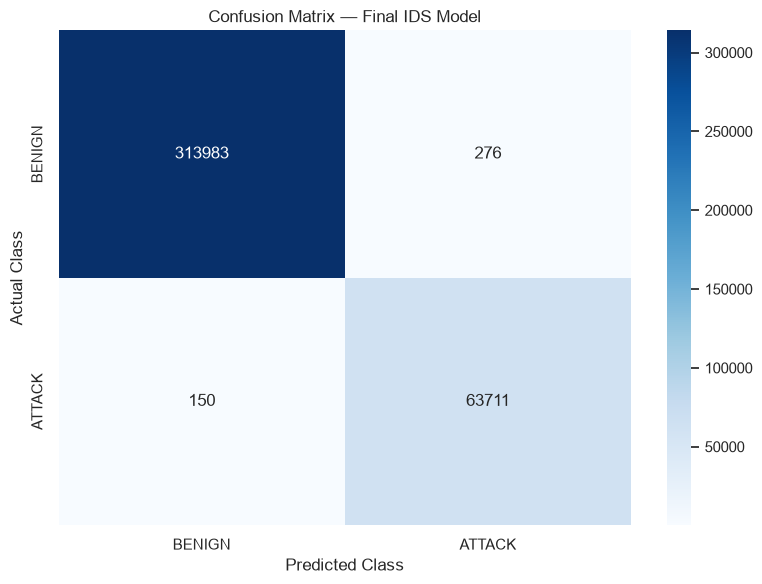

Confusion matrix saved to:
D:\AI-IDS\results\figures\final_confusion_matrix.png


In [15]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["BENIGN", "ATTACK"],
    yticklabels=["BENIGN", "ATTACK"]
)

plt.title("Confusion Matrix — Final IDS Model")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

confusion_matrix_path = (
    RESULTS_FIGURES_DIR / "final_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved to:")
print(confusion_matrix_path)

**Classification Report**

In [16]:
report = classification_report(
    y_test,
    y_pred,
    target_names=["BENIGN", "ATTACK"],
    output_dict=True,
    zero_division=0
)

classification_report_df = pd.DataFrame(report).transpose()

display(classification_report_df)

,precision,recall,f1-score,support
BENIGN,0.999522,0.999122,0.999322,314259.000000
ATTACK,0.995687,0.997651,0.996668,63861.000000
accuracy,0.998873,0.998873,0.998873,0.998873
macro avg,0.997605,0.998386,0.997995,378120.000000
weighted avg,0.998875,0.998873,0.998874,378120.000000


**Save Classification Report**

In [17]:
classification_report_path = (
    RESULTS_METRICS_DIR / "classification_report.csv"
)

classification_report_df.to_csv(
    classification_report_path
)

print("Classification report saved to:")
print(classification_report_path)

Classification report saved to:
D:\AI-IDS\results\metrics\classification_report.csv


**ROC Curve and ROC-AUC**

In [18]:
# Obtain continuous prediction scores

if hasattr(final_model, "predict_proba"):
    y_score = final_model.predict_proba(X_test)[:, 1]

elif hasattr(final_model, "decision_function"):
    y_score = final_model.decision_function(X_test)

else:
    raise AttributeError(
        "The final model does not provide predict_proba "
        "or decision_function."
    )

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_score
)

roc_auc = roc_auc_score(
    y_test,
    y_score
)

print(f"ROC-AUC: {roc_auc:.6f}")

ROC-AUC: 0.999768


**ROC Curve Visualization**

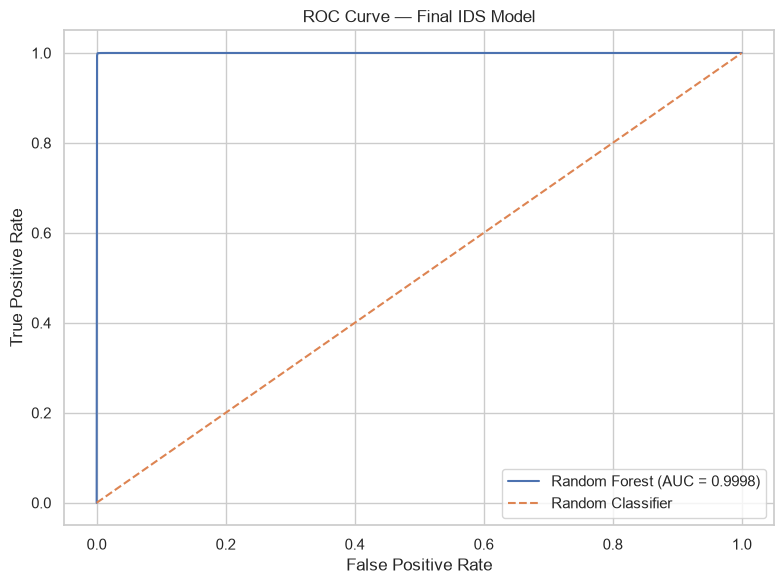

ROC curve saved to:
D:\AI-IDS\results\figures\roc_curve.png


In [19]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve — Final IDS Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(True)

plt.tight_layout()

roc_curve_path = (
    RESULTS_FIGURES_DIR / "roc_curve.png"
)

plt.savefig(
    roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved to:")
print(roc_curve_path)

**Precision-Recall Curve**

In [20]:
precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_test,
        y_score
    )
)

pr_auc = auc(
    recall_curve,
    precision_curve
)

print(f"PR-AUC: {pr_auc:.6f}")

PR-AUC: 0.998871


**Precision-Recall Visualization**

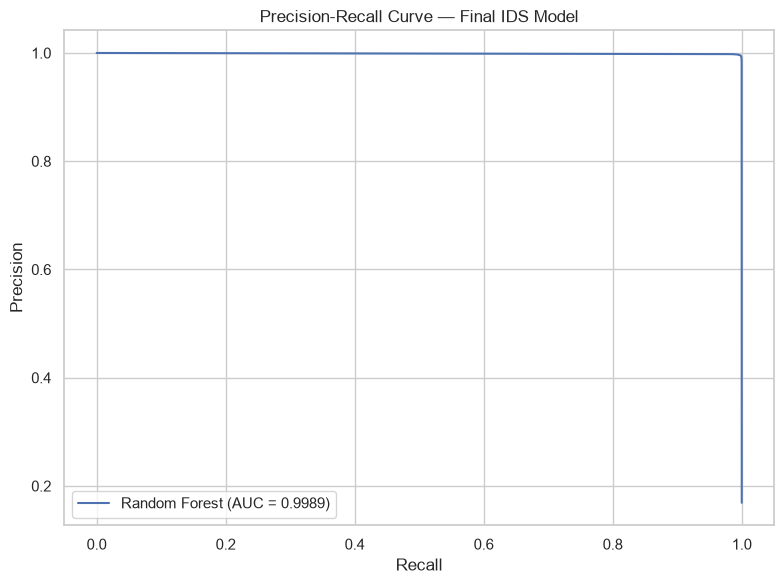

Precision-Recall curve saved to:
D:\AI-IDS\results\figures\precision_recall_curve.png


In [21]:
plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Random Forest (AUC = {pr_auc:.4f})"
)

plt.title("Precision-Recall Curve — Final IDS Model")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.grid(True)

plt.tight_layout()

pr_curve_path = (
    RESULTS_FIGURES_DIR / "precision_recall_curve.png"
)

plt.savefig(
    pr_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Precision-Recall curve saved to:")
print(pr_curve_path)

**Complete Evaluation Metrics**

In [22]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "False Positive Rate",
        "False Negative Rate",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        fpr_value,
        fnr_value,
        roc_auc,
        pr_auc
    ]
})

display(final_metrics)

,Metric,Score
0,Accuracy,0.998873
1,Precision,0.995687
2,Recall,0.997651
3,F1-Score,0.996668
4,False Positive Rate,0.000878
5,False Negative Rate,0.002349
6,ROC-AUC,0.999768
7,PR-AUC,0.998871


**Save Final Evaluation Metrics**

In [23]:
final_metrics_path = (
    RESULTS_METRICS_DIR / "final_test_evaluation.csv"
)

final_metrics.to_csv(
    final_metrics_path,
    index=False
)

print("Final evaluation metrics saved to:")
print(final_metrics_path)

Final evaluation metrics saved to:
D:\AI-IDS\results\metrics\final_test_evaluation.csv


**Save Confusion Matrix Values**

In [24]:
confusion_matrix_df = pd.DataFrame(
    cm,
    index=["Actual BENIGN", "Actual ATTACK"],
    columns=["Predicted BENIGN", "Predicted ATTACK"]
)

display(confusion_matrix_df)

confusion_matrix_csv_path = (
    RESULTS_METRICS_DIR / "confusion_matrix.csv"
)

confusion_matrix_df.to_csv(
    confusion_matrix_csv_path
)

print("Confusion matrix values saved to:")
print(confusion_matrix_csv_path)

,Predicted BENIGN,Predicted ATTACK
Actual BENIGN,313983,276
Actual ATTACK,150,63711


Confusion matrix values saved to:
D:\AI-IDS\results\metrics\confusion_matrix.csv
